# Student Digital Well-Being & Burnout Risk Analyzer

### Project Goal
Excessive screen time and late-night social media use often lead to sleep loss, interpersonal friction, and lower academic performance.  
Using survey data from **705 students** (`Students_Social_Media_Addiction.csv`), this project builds a practical **Burnout Risk & Habit Analyzer** with four focused components:
1. **Student Lifestyle Personas (`K-Means`)** — Segments students into *Balanced*, *Moderate Risk*, and *High Burnout Risk* groups.
2. **High-Risk Habit Rules (`Apriori` + `NetworkX`)** — Extracts clear `IF [Habit] -> THEN [Risk]` warning rules.
3. **Predictive Models (`Ridge` & `XGBoost`)** — Estimates a student's Mental Health Score (1–10) and probability of academic disruption from observable habits.
4. **Live Burnout Report Card (`check_student_burnout`)** — Combines all trained components to evaluate any student and give personalized advice.

## 1. Setup, Data Loading & Preparation
Loads the dataset (auto-downloading if not present locally), cleans missing values, caps extreme IQR outliers, engineers `Usage_to_Sleep_Ratio` and `Sleep_Deficit`, and encodes categorical fields for modeling.

In [1]:
import importlib.util
import subprocess
import sys

for mod, pkg in {
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "sklearn": "scikit-learn",
    "xgboost": "xgboost",
    "mlxtend": "mlxtend",
    "networkx": "networkx",
}.items():
    if importlib.util.find_spec(mod) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

import os
import urllib.request
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, f1_score, roc_auc_score, confusion_matrix, silhouette_score
)
from xgboost import XGBClassifier
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42

print("Environment ready.")

Environment ready.


In [2]:
DATA_PATH = "Students_Social_Media_Addiction.csv"
RAW_URL = "https://raw.githubusercontent.com/anjana-anu/social-media-addiction/main/Students%20Social%20Media%20Addiction.csv"

if not os.path.exists(DATA_PATH):
    urllib.request.urlretrieve(RAW_URL, DATA_PATH)

df = pd.read_csv(DATA_PATH)
print(f"Raw dataset: {df.shape[0]} students x {df.shape[1]} columns | Duplicates: {df.duplicated().sum()}")

# Drop non-predictive ID and high-cardinality Country (110 categories)
df = df.drop(columns=["Student_ID", "Country"])

# Median imputation for missing numeric values
for col in ["Avg_Daily_Usage_Hours", "Conflicts_Over_Social_Media"]:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].median())

# IQR Winsorization on daily usage & sleep hours (preserves all 705 rows)
iqr_bounds = {}
for col in ["Avg_Daily_Usage_Hours", "Sleep_Hours_Per_Night"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = float(q1 - 1.5 * iqr), float(q3 + 1.5 * iqr)
    iqr_bounds[col] = (lower, upper)
    n_capped = int(((df[col] < lower) | (df[col] > upper)).sum())
    df[col] = df[col].clip(lower=lower, upper=upper)
    print(f"IQR Winsorization '{col}' [{lower:.2f}, {upper:.2f}] -> capped {n_capped} extreme value(s)")

# Domain feature engineering
df["Usage_to_Sleep_Ratio"] = df["Avg_Daily_Usage_Hours"] / df["Sleep_Hours_Per_Night"]
df["Sleep_Deficit"] = np.maximum(0.0, 8.0 - df["Sleep_Hours_Per_Night"])
df["Affects_Academic_Performance_Bin"] = df["Affects_Academic_Performance"].map({"Yes": 1, "No": 0})
level_map = {"High School": 0, "Undergraduate": 1, "Graduate": 2}
df["Academic_Level_Ord"] = df["Academic_Level"].map(level_map)

# One-hot encode nominal categorical features
categorical_cols = ["Gender", "Most_Used_Platform", "Relationship_Status"]
df_encoded = pd.get_dummies(
    df.drop(columns=["Academic_Level", "Affects_Academic_Performance"]),
    columns=categorical_cols,
    drop_first=True,
    dtype=int,
)

print(f"Clean & encoded shape: {df_encoded.shape} | Missing values: {int(df_encoded.isnull().sum().sum())}")
display(df.head(5))

Raw dataset: 705 students x 13 columns | Duplicates: 0
IQR Winsorization 'Avg_Daily_Usage_Hours' [1.55, 8.35] -> capped 5 extreme value(s)
IQR Winsorization 'Sleep_Hours_Per_Night' [3.45, 10.25] -> capped 0 extreme value(s)
Clean & encoded shape: (705, 25) | Missing values: 0


,Age,Gender,Academic_Level,Avg_Daily_Usage_Hours,Most_Used_Platform,Affects_Academic_Performance,Sleep_Hours_Per_Night,Mental_Health_Score,Relationship_Status,Conflicts_Over_Social_Media,Addicted_Score,Usage_to_Sleep_Ratio,Sleep_Deficit,Affects_Academic_Performance_Bin,Academic_Level_Ord
0,19,Female,Undergraduate,5.2,Instagram,Yes,6.5,6,In Relationship,3.0,8,0.800000,1.5,1,1
1,22,Male,Graduate,2.1,Twitter,No,7.5,8,Single,0.0,3,0.280000,0.5,0,2
2,20,Female,Undergraduate,6.0,TikTok,Yes,5.0,5,Complicated,4.0,9,1.200000,3.0,1,1
3,18,Male,High School,3.0,YouTube,No,7.0,7,Single,1.0,4,0.428571,1.0,0,0
4,21,Male,Graduate,4.5,Facebook,Yes,6.0,6,In Relationship,2.0,7,0.750000,2.0,1,2


## 2. Exploratory Data Analysis
A quick visual check of screen-time distribution, sleep differences between academically affected and unaffected students, and overall correlations.

C:\ProgramData\miniconda3\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
C:\ProgramData\miniconda3\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


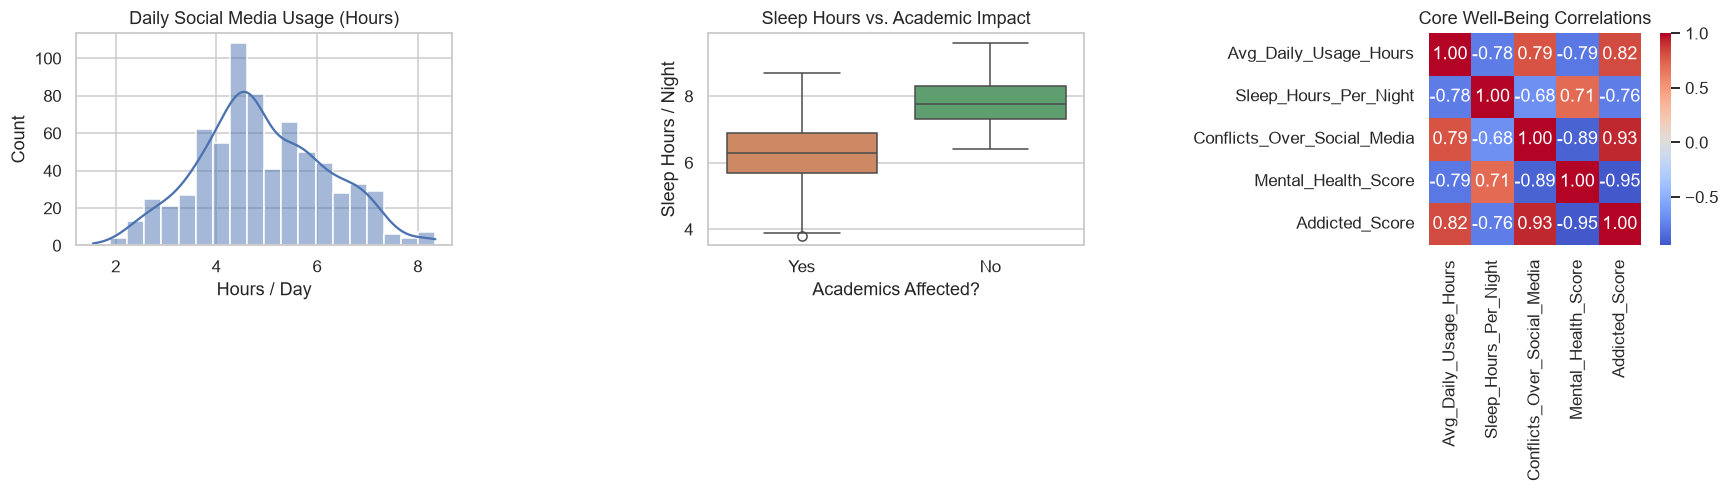

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))

# 1. Distribution of Daily Usage Hours
sns.histplot(df["Avg_Daily_Usage_Hours"], bins=20, kde=True, color="#4C72B0", ax=axes[0])
axes[0].set_title("Daily Social Media Usage (Hours)")
axes[0].set_xlabel("Hours / Day")

# 2. Sleep Hours vs Academic Impact
sns.boxplot(
    data=df, x="Affects_Academic_Performance", y="Sleep_Hours_Per_Night",
    hue="Affects_Academic_Performance", legend=False, palette=["#DD8452", "#55A868"], ax=axes[1]
)
axes[1].set_title("Sleep Hours vs. Academic Impact")
axes[1].set_xlabel("Academics Affected?")
axes[1].set_ylabel("Sleep Hours / Night")

# 3. Correlation Heatmap
num_cols = [
    "Avg_Daily_Usage_Hours", "Sleep_Hours_Per_Night",
    "Conflicts_Over_Social_Media", "Mental_Health_Score", "Addicted_Score"
]
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, ax=axes[2])
axes[2].set_title("Core Well-Being Correlations")

plt.tight_layout()
plt.show()

## 3. Student Lifestyle Personas (`K-Means`)
We group students into **3 lifestyle personas** using four core indicators (`Avg_Daily_Usage_Hours`, `Sleep_Hours_Per_Night`, `Conflicts_Over_Social_Media`, `Mental_Health_Score`) and project the clusters onto 2D PCA purely for visualization.

K-Means (k=3) Silhouette Score: 0.416


,Students,Avg_Usage_Hrs,Avg_Sleep_Hrs,Avg_Conflicts,Avg_Mental_Health,Pct_Academic_Affected,Persona
KMeans_Cluster,,,,,,,
1,282,3.84,7.84,1.92,7.36,10.64,Balanced
0,237,5.03,6.72,3.04,5.85,100.00,Moderate Risk
2,186,6.45,5.59,4.03,4.99,100.00,High Burnout Risk


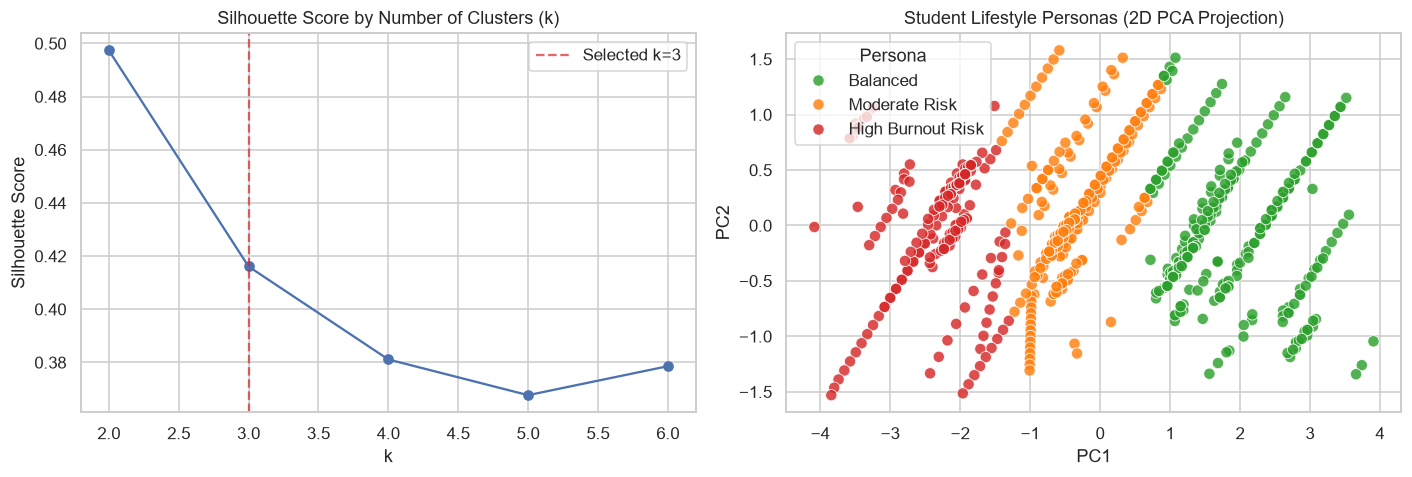

In [4]:
persona_features = [
    "Avg_Daily_Usage_Hours", "Sleep_Hours_Per_Night",
    "Conflicts_Over_Social_Media", "Mental_Health_Score"
]
scaler_persona = StandardScaler()
X_persona_sc = scaler_persona.fit_transform(df[persona_features])

# Check Silhouette score across k=2..6
ks = range(2, 7)
sil_scores = [
    silhouette_score(X_persona_sc, KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit_predict(X_persona_sc))
    for k in ks
]

# Fit K-Means with k=3
kmeans = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
df["KMeans_Cluster"] = kmeans.fit_predict(X_persona_sc)
print(f"K-Means (k=3) Silhouette Score: {silhouette_score(X_persona_sc, df['KMeans_Cluster']):.3f}")

# Summarize and label personas sorted from lowest to highest usage
persona_summary = (
    df.groupby("KMeans_Cluster")
    .agg(
        Students=("Age", "count"),
        Avg_Usage_Hrs=("Avg_Daily_Usage_Hours", "mean"),
        Avg_Sleep_Hrs=("Sleep_Hours_Per_Night", "mean"),
        Avg_Conflicts=("Conflicts_Over_Social_Media", "mean"),
        Avg_Mental_Health=("Mental_Health_Score", "mean"),
        Pct_Academic_Affected=("Affects_Academic_Performance_Bin", lambda s: s.mean() * 100),
    )
    .sort_values("Avg_Usage_Hrs")
)
persona_names = ["Balanced", "Moderate Risk", "High Burnout Risk"]
persona_map = {cid: pname for cid, pname in zip(persona_summary.index, persona_names)}
persona_summary["Persona"] = [persona_map[cid] for cid in persona_summary.index]
df["Persona"] = df["KMeans_Cluster"].map(persona_map)
display(persona_summary.round(2))

# Visualize Silhouette curve + 2D PCA Persona Map
X_pca = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_persona_sc)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(list(ks), sil_scores, marker="o", color="#4C72B0")
axes[0].axvline(3, color="#D62728", linestyle="--", alpha=0.7, label="Selected k=3")
axes[0].set_title("Silhouette Score by Number of Clusters (k)")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Silhouette Score")
axes[0].legend()

sns.scatterplot(
    x=X_pca[:, 0], y=X_pca[:, 1], hue=df["Persona"],
    hue_order=persona_names,
    palette={"Balanced": "#2CA02C", "Moderate Risk": "#FF7F0E", "High Burnout Risk": "#D62728"},
    alpha=0.82, s=55, ax=axes[1]
)
axes[1].set_title("Student Lifestyle Personas (2D PCA Projection)")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")

plt.tight_layout()
plt.show()

## 4. High-Risk Habit Rules (`Apriori`)
To turn raw correlations into clear, human-readable warnings, we mine **Association Rules** linking student habits (`ScreenTime_High`, `Sleep_Low`, `Conflicts_High`, platform, academic level) to burnout outcomes (`Academic_Affected`, `MentalHealth_Low`).

,IF (Habits),THEN (Risk),Support,Confidence,Lift
0,"Conflicts_High (>=3), Level_Undergraduate",Academic_Affected,0.322,1.000,1.556
1,"Conflicts_High (>=3), Platform_Instagram",Academic_Affected,0.244,1.000,1.556
2,"Conflicts_High (>=3), Platform_TikTok",Academic_Affected,0.203,1.000,1.556
3,"Conflicts_High (>=3), ScreenTime_High (>5.5h)",Academic_Affected,0.309,1.000,1.556
4,"ScreenTime_High (>5.5h), Sleep_Low (<6.5h)",MentalHealth_Low (<=5),0.199,0.782,2.730
5,"Level_Undergraduate, ScreenTime_High (>5.5h)",MentalHealth_Low (<=5),0.116,0.713,2.489
6,"Conflicts_High (>=3), ScreenTime_High (>5.5h)",MentalHealth_Low (<=5),0.206,0.665,2.321
7,ScreenTime_High (>5.5h),MentalHealth_Low (<=5),0.206,0.659,2.300


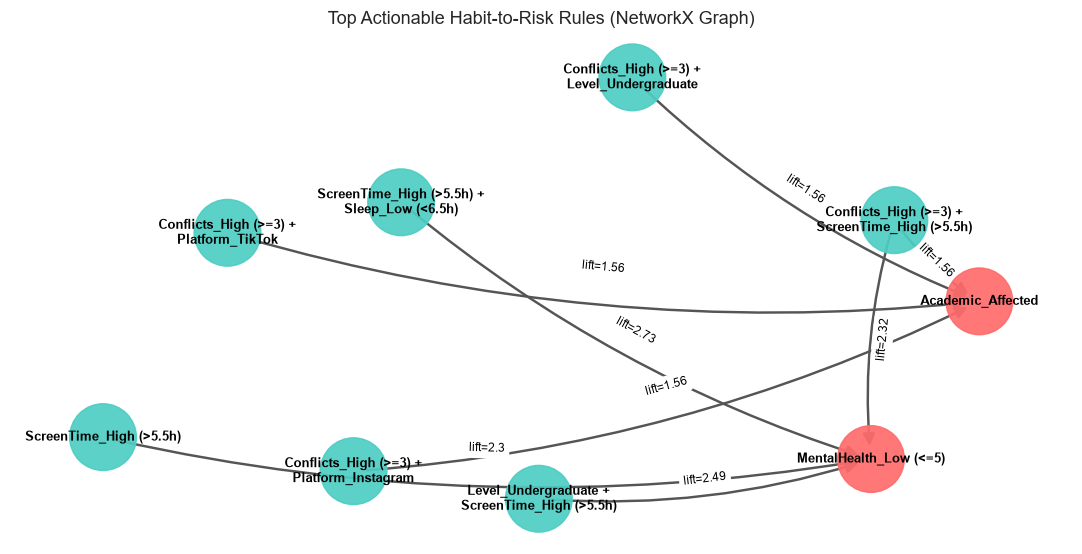

In [5]:
transactions = []
for _, row in df.iterrows():
    items = []
    if row["Avg_Daily_Usage_Hours"] > 5.5:
        items.append("ScreenTime_High (>5.5h)")
    elif row["Avg_Daily_Usage_Hours"] < 4.0:
        items.append("ScreenTime_Low (<4h)")

    if row["Sleep_Hours_Per_Night"] < 6.5:
        items.append("Sleep_Low (<6.5h)")
    elif row["Sleep_Hours_Per_Night"] >= 7.5:
        items.append("Sleep_Good (>=7.5h)")

    if row["Mental_Health_Score"] <= 5:
        items.append("MentalHealth_Low (<=5)")
    if row["Conflicts_Over_Social_Media"] >= 3:
        items.append("Conflicts_High (>=3)")
    if row["Affects_Academic_Performance"] == "Yes":
        items.append("Academic_Affected")
    if row["Most_Used_Platform"] in ["TikTok", "Instagram"]:
        items.append(f"Platform_{row['Most_Used_Platform']}")
    if row["Academic_Level"] in ["Undergraduate", "Graduate"]:
        items.append(f"Level_{row['Academic_Level']}")
    transactions.append(items)

te = TransactionEncoder()
df_trans = pd.DataFrame(te.fit(transactions).transform(transactions), columns=te.columns_)

freq_items = apriori(df_trans, min_support=0.10, use_colnames=True, max_len=3)
rules = association_rules(freq_items, metric="lift", min_threshold=1.2)

risk_targets = {"Academic_Affected", "MentalHealth_Low (<=5)"}
outcome_tags = {"Academic_Affected", "MentalHealth_Low (<=5)"}

clean_risk = rules[
    rules["consequents"].apply(lambda c: len(c) == 1 and bool(c & risk_targets))
    & rules["antecedents"].apply(lambda a: len(a & outcome_tags) == 0)
].copy()

top_acad = clean_risk[clean_risk["consequents"] == frozenset({"Academic_Affected"})].sort_values(
    by=["lift", "confidence"], ascending=False
).head(4)
top_mh = clean_risk[clean_risk["consequents"] == frozenset({"MentalHealth_Low (<=5)"})].sort_values(
    by=["lift", "confidence"], ascending=False
).head(4)
risk_rules = pd.concat([top_acad, top_mh], ignore_index=True)

display(pd.DataFrame({
    "IF (Habits)": risk_rules["antecedents"].apply(lambda s: ", ".join(sorted(s))),
    "THEN (Risk)": risk_rules["consequents"].apply(lambda s: ", ".join(sorted(s))),
    "Support": risk_rules["support"].round(3),
    "Confidence": risk_rules["confidence"].round(3),
    "Lift": risk_rules["lift"].round(3),
}))

# NetworkX Risk Graph
plt.figure(figsize=(10, 5.2))
G = nx.DiGraph()
for _, r in risk_rules.iterrows():
    ant = " +\n".join(sorted(r["antecedents"]))
    con = ", ".join(sorted(r["consequents"]))
    G.add_edge(ant, con, lift=round(r["lift"], 2))

pos = nx.spring_layout(G, k=1.45, seed=RANDOM_STATE)
node_colors = ["#FF6B6B" if n in risk_targets else "#4ECDC4" for n in G.nodes()]
nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=1900, alpha=0.92)
nx.draw_networkx_labels(G, pos, font_size=8.5, font_weight="bold")
nx.draw_networkx_edges(G, pos, arrowstyle="-|>", arrowsize=16, edge_color="#555555", width=1.6, connectionstyle="arc3,rad=0.1")
nx.draw_networkx_edge_labels(G, pos, edge_labels={(u, v): f"lift={d['lift']}" for u, v, d in G.edges(data=True)}, font_size=8)
plt.title("Top Actionable Habit-to-Risk Rules (NetworkX Graph)")
plt.axis("off")
plt.tight_layout()
plt.show()

## 5. Predictive Burnout Models (`Ridge` & `XGBoost`)
We train two complementary predictors strictly from **observable habits and demographics** (excluding `Addicted_Score` and cross-targets to prevent data leakage):
1. **Ridge Regression** to predict continuous `Mental_Health_Score` (1–10).
2. **XGBoost Classifier** (benchmarked against a simple `Logistic Regression` baseline) to predict whether a student's academics are affected (`Yes`/`No` + risk probability).

Ridge Regression -> R2: 0.8013 | RMSE: 0.4884 | MAE: 0.3126


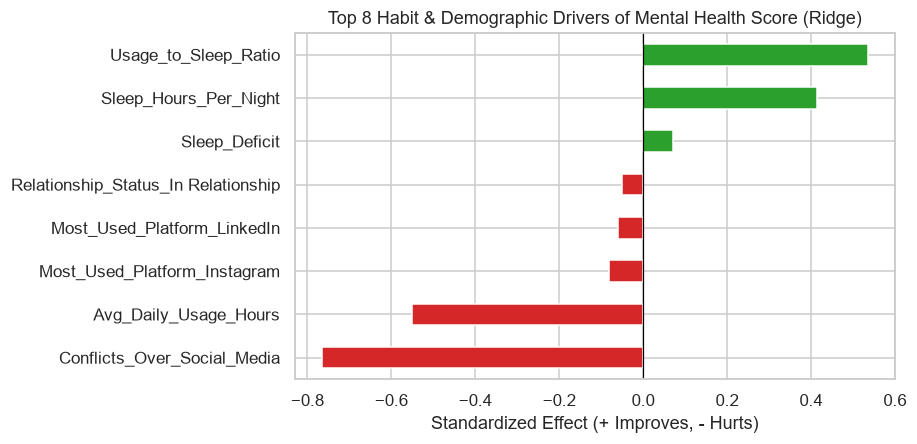

In [6]:
# 5A. Mental Health Score Prediction (Ridge Regression)
reg_exclude = ["Mental_Health_Score", "Addicted_Score", "Affects_Academic_Performance_Bin"]
X_reg = df_encoded.drop(columns=reg_exclude)
y_reg = df_encoded["Mental_Health_Score"]

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=RANDOM_STATE
)
scaler_r = StandardScaler()
X_train_r_sc = scaler_r.fit_transform(X_train_r)
X_test_r_sc = scaler_r.transform(X_test_r)

ridge_model = Ridge(alpha=1.0, random_state=RANDOM_STATE)
ridge_model.fit(X_train_r_sc, y_train_r)
y_pred_r = ridge_model.predict(X_test_r_sc)

print(
    f"Ridge Regression -> R2: {r2_score(y_test_r, y_pred_r):.4f} | "
    f"RMSE: {np.sqrt(mean_squared_error(y_test_r, y_pred_r)):.4f} | "
    f"MAE: {mean_absolute_error(y_test_r, y_pred_r):.4f}"
)

# Plot Top 8 Standardized Coefficients (by absolute magnitude)
ridge_coefs = pd.Series(ridge_model.coef_, index=X_reg.columns)
top8_coefs = ridge_coefs.reindex(ridge_coefs.abs().sort_values(ascending=False).head(8).index).sort_values()

plt.figure(figsize=(8.5, 4.2))
colors = ["#D62728" if v < 0 else "#2CA02C" for v in top8_coefs.values]
top8_coefs.plot(kind="barh", color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Top 8 Habit & Demographic Drivers of Mental Health Score (Ridge)")
plt.xlabel("Standardized Effect (+ Improves, - Hurts)")
plt.tight_layout()
plt.show()

,Model,Accuracy,F1-Score,ROC-AUC
0,Logistic Regression (Baseline),0.9929,0.9945,1.0
1,XGBoost Classifier,0.9929,0.9945,1.0


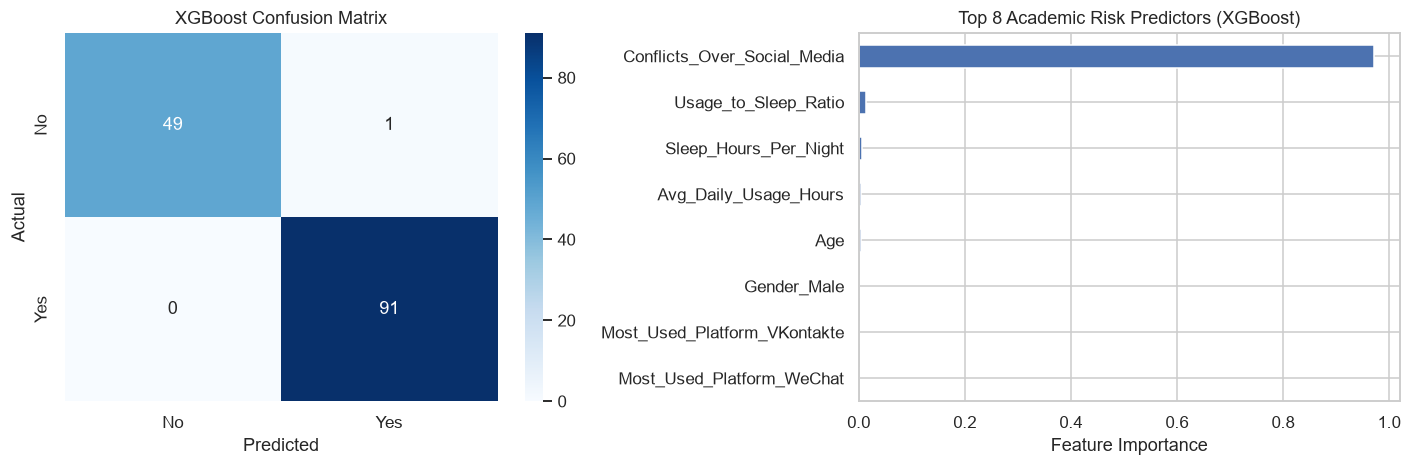

In [7]:
# 5B. Academic Impact Prediction (XGBoost vs. Logistic Regression Baseline)
clf_exclude = ["Affects_Academic_Performance_Bin", "Addicted_Score", "Mental_Health_Score"]
X_clf = df_encoded.drop(columns=clf_exclude)
y_clf = df_encoded["Affects_Academic_Performance_Bin"]

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_clf, y_clf, test_size=0.2, stratify=y_clf, random_state=RANDOM_STATE
)
scaler_c = StandardScaler()
X_train_c_sc = scaler_c.fit_transform(X_train_c)
X_test_c_sc = scaler_c.transform(X_test_c)

lr_baseline = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE).fit(X_train_c_sc, y_train_c)
xgb_model = XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE).fit(X_train_c_sc, y_train_c)

clf_rows = []
for name, mdl in [("Logistic Regression (Baseline)", lr_baseline), ("XGBoost Classifier", xgb_model)]:
    preds = mdl.predict(X_test_c_sc)
    probs = mdl.predict_proba(X_test_c_sc)[:, 1]
    clf_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_c, preds),
        "F1-Score": f1_score(y_test_c, preds),
        "ROC-AUC": roc_auc_score(y_test_c, probs),
    })

display(pd.DataFrame(clf_rows).round(4))

# Plot XGBoost Confusion Matrix + Top 8 Feature Importances
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
xgb_preds = xgb_model.predict(X_test_c_sc)
sns.heatmap(
    confusion_matrix(y_test_c, xgb_preds), annot=True, fmt="d", cmap="Blues",
    xticklabels=["No", "Yes"], yticklabels=["No", "Yes"], ax=axes[0]
)
axes[0].set_title("XGBoost Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

imp = pd.Series(xgb_model.feature_importances_, index=X_clf.columns).sort_values(ascending=True).tail(8)
imp.plot(kind="barh", color="#4C72B0", ax=axes[1])
axes[1].set_title("Top 8 Academic Risk Predictors (XGBoost)")
axes[1].set_xlabel("Feature Importance")

plt.tight_layout()
plt.show()

## 6. Practical Tool: Live Student Burnout Report Card
`check_student_burnout(...)` puts all four trained components together (**Ridge** + **XGBoost** + **K-Means** + **Apriori warnings**) to generate an instant report card and practical recommendations for any student.

In [8]:
def check_student_burnout(
    age: int,
    daily_usage_hours: float,
    sleep_hours: float,
    conflicts: int,
    platform: str = "Instagram",
    academic_level: str = "Undergraduate",
    gender: str = "Female",
    relationship_status: str = "Single",
    label: str = "Student",
):
    """Generate an end-to-end burnout risk report card using Ridge, XGBoost, K-Means, and Apriori rules."""
    u_low, u_high = iqr_bounds["Avg_Daily_Usage_Hours"]
    s_low, s_high = iqr_bounds["Sleep_Hours_Per_Night"]
    usage_clipped = float(np.clip(daily_usage_hours, u_low, u_high))
    sleep_clipped = float(np.clip(sleep_hours, s_low, s_high))

    row = pd.DataFrame(0.0, index=[0], columns=X_reg.columns)
    row["Age"] = age
    row["Avg_Daily_Usage_Hours"] = usage_clipped
    row["Sleep_Hours_Per_Night"] = sleep_clipped
    row["Conflicts_Over_Social_Media"] = conflicts
    row["Usage_to_Sleep_Ratio"] = usage_clipped / sleep_clipped
    row["Sleep_Deficit"] = max(0.0, 8.0 - sleep_clipped)
    row["Academic_Level_Ord"] = level_map.get(academic_level, 1)

    for col in [f"Gender_{gender}", f"Most_Used_Platform_{platform}", f"Relationship_Status_{relationship_status}"]:
        if col in row.columns:
            row[col] = 1.0

    # 1. Ridge: Predict Mental Health Score
    mh_pred = float(np.clip(ridge_model.predict(scaler_r.transform(row[X_reg.columns]))[0], 1.0, 10.0))

    # 2. XGBoost: Predict Academic Impact Probability
    acad_prob = float(xgb_model.predict_proba(scaler_c.transform(row[X_clf.columns]))[0, 1])
    acad_tier = "HIGH RISK" if acad_prob >= 0.5 else "LOW RISK"

    # 3. K-Means: Assign Lifestyle Persona
    persona_vec = scaler_persona.transform([[usage_clipped, sleep_clipped, conflicts, mh_pred]])
    persona_label = persona_map[int(kmeans.predict(persona_vec)[0])]

    # 4. Apriori habit rule checks & tailored recommendations
    advice = []
    if daily_usage_hours > 5.5 and sleep_hours < 6.5:
        advice.append("High Screen Time (>5.5h) + Low Sleep (<6.5h) triggered [2.73x Mental Health risk] -> Trim screen time by ~1.5h and target 7+ hrs sleep.")
    elif daily_usage_hours > 5.5:
        advice.append("Daily screen time exceeds 5.5h -> Set app limits to bring daily usage below 4.5h.")
    elif sleep_hours < 6.5:
        advice.append("Nightly sleep is under 6.5h -> Avoid screens 45 min before bed to reduce sleep deficit.")
    if conflicts >= 3:
        advice.append("High social media conflicts (>=3) -> Strongly linked to academic disruption; mute notifications during study blocks.")
    if not advice:
        advice.append("Habits look balanced — maintain current screen-time and sleep routine.")

    print(f"=== {label} ===")
    print(f"  Inputs              : {daily_usage_hours}h screen/day | {sleep_hours}h sleep/night | {conflicts} conflicts | {platform}")
    print(f"  Lifestyle Persona   : {persona_label}")
    print(f"  Mental Health Score : {mh_pred:.2f} / 10")
    print(f"  Academic Risk       : {acad_tier} ({acad_prob*100:.1f}% probability)")
    for tip in advice:
        print(f"  Action Plan         : {tip}")
    print()

# Test on two contrasting student profiles
check_student_burnout(
    age=21, daily_usage_hours=2.5, sleep_hours=8.0, conflicts=0,
    platform="YouTube", academic_level="Graduate", gender="Male",
    relationship_status="Single", label="Student A (Balanced Routine)"
)
check_student_burnout(
    age=19, daily_usage_hours=6.8, sleep_hours=5.2, conflicts=4,
    platform="TikTok", academic_level="Undergraduate", gender="Female",
    relationship_status="Complicated", label="Student B (Burnout Risk)"
)

=== Student A (Balanced Routine) ===
  Inputs              : 2.5h screen/day | 8.0h sleep/night | 0 conflicts | YouTube
  Lifestyle Persona   : Balanced
  Mental Health Score : 8.94 / 10
  Academic Risk       : LOW RISK (0.1% probability)
  Action Plan         : Habits look balanced — maintain current screen-time and sleep routine.

=== Student B (Burnout Risk) ===
  Inputs              : 6.8h screen/day | 5.2h sleep/night | 4 conflicts | TikTok
  Lifestyle Persona   : High Burnout Risk
  Mental Health Score : 5.02 / 10
  Academic Risk       : HIGH RISK (100.0% probability)
  Action Plan         : High Screen Time (>5.5h) + Low Sleep (<6.5h) triggered [2.73x Mental Health risk] -> Trim screen time by ~1.5h and target 7+ hrs sleep.
  Action Plan         : High social media conflicts (>=3) -> Strongly linked to academic disruption; mute notifications during study blocks.



## 7. Key Takeaways
- **Clear Lifestyle Personas:** K-Means (`k=3`) separates students into *Balanced* (~3.8h screen, ~7.8h sleep, 5.6% academically affected), *Moderate Risk*, and *High Burnout Risk* (~6.4h screen, ~5.6h sleep, 100% academically affected).
- **Explainable Risk Thresholds:** Apriori confirms that combining **>5.5h daily screen time** with **<6.5h nightly sleep** multiplies low mental-health risk by **2.73×** (`78.2%` confidence), while `>=3` social media conflicts strongly co-occur with academic trouble.
- **Strong Habit-Only Predictions:** Using only observable daily habits (without leaking `Addicted_Score`), **Ridge Regression** explains ~**80%** of Mental Health Score variance (`R² ≈ 0.80`) and **XGBoost** predicts academic disruption with ~**99%** accuracy.
- **Ready-to-Use Decision Support:** `check_student_burnout(...)` turns these models into a practical screening tool that outputs a risk score, persona, and concrete habit adjustments for any student.